# 구글 드라이브 연결

In [1]:
from google.colab import drive

drive.mount('/content/data')

Mounted at /content/data


In [2]:
import sys

sys.path.append(
    "/content/data/MyDrive/colab tutorial"
)

In [3]:
from deep_learning import *

# Load Data

In [4]:
import torch
import torchvision
import torchvision.transforms as transforms

train_dataset = torchvision.datasets.CIFAR10(
    root='/content/data/MyDrive/colab tutorial/data', train=True,
                                       download=False, transform=transforms.ToTensor())

test_dataset = torchvision.datasets.CIFAR10(
    root='/content/data/MyDrive/colab tutorial/data', train=False,
                                       download=False, transform=transforms.ToTensor())
len(train_dataset), len(test_dataset)

(50000, 10000)

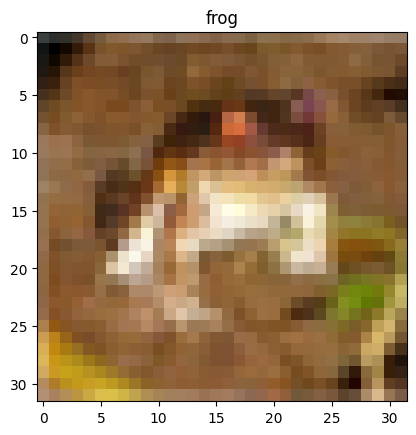

In [5]:
import matplotlib.pyplot as plt

feature, target = train_dataset[0]
plt.title(train_dataset.classes[target])
plt.imshow(feature.permute(1,2,0).numpy())
plt.show()

# DataLoader 클래스 생성

In [6]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=True)

len(train_dataloader), len(test_dataloader)

(782, 157)

In [7]:
features, targets = next(iter(train_dataloader))

# (batch, color, row, column)
features.shape, targets.shape

(torch.Size([64, 3, 32, 32]), torch.Size([64]))

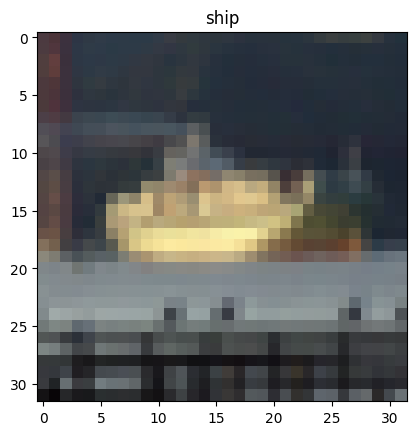

In [8]:
plt.title(train_dataset.classes[targets[0]])
plt.imshow(features[0].permute(1,2,0).numpy())
plt.show()

# CNN

## nn.Conv2d(in_channels, out_channels, kernel_size)

> 흑백 이미지일 때,

![](https://coolgpu.github.io/coolgpu_blog/assets/images/Conv2d_0p_1s_1inCh.gif)

> 컬러 이미지일 때,

![](https://coolgpu.github.io/coolgpu_blog/assets/images/Conv2d_0p_1s_3inCh.gif)

[output tensor size](https://velog.io/@tobigs1516_image/Convolutional-Neural-Networks):

- O: Size(width) of output image
- I: Size(width) of input image
- K: Size(width) of kernels used in the Conv layer
- N: Number of kernels
- S: Stride of the convolution operation
- P: Padding size  

$$
O = { I - K + 2P \over S } + 1
$$

In [9]:
from torch import nn

# nn.Conv2d(input_size, output_size, kernel_size, ...)
# => input_size: color_size(=3)
conv = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=3)

In [10]:
# (batch, color, row, column)
features.shape

torch.Size([64, 3, 32, 32])

In [11]:
out_conv = conv(features.to(dtype=torch.float32))

# (batch, feature_map(out_channels), feature_row, feature_column)
out_conv.shape

torch.Size([64, 10, 30, 30])

## [nn.MaxPool2d()](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html)
- `kernel_size`: the size of the window to take a max over
- `stride`: the stride of the window. Default value is `kernel_size`

In [12]:
pool = nn.MaxPool2d(3, stride=2)

In [13]:
out_pool = pool(out_conv)

# pool을 사용하면, batch와 feature_map는 변경되지 않음
# => feature_row, feature_column만 변경됨!
out_pool.shape

torch.Size([64, 10, 14, 14])

In [14]:
out_pool.reshape(20, -1).shape

torch.Size([20, 6272])

In [15]:
nn.Flatten()(out_pool).shape

torch.Size([64, 1960])

## Conv Layer

In [16]:
class ConvLayer(nn.Module):
    def __init__(self, in_channels, out_channels=10):
        super().__init__()
        self.sequential = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(out_channels, out_channels, kernel_size=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

    def forward(self, x): # (batch, color, row, column)
        return self.sequential(x)

In [17]:
conv_layer = ConvLayer(in_channels=3)

In [18]:
input = features

out_conv = conv_layer(input)
# (batch, feature_map(out_channels), feature_row, feature_column)
out_conv.shape

torch.Size([64, 10, 7, 7])

## Dense Layer

In [19]:
class DenseLayer(nn.Module):
    def __init__(self, feature_size, target_size, hidden_size=10):
        super().__init__()
        self.sequential = nn.Sequential(
            nn.Flatten(),
            nn.Linear(feature_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, target_size),
        )

    def forward(self, x): # (batch, color, row, column)
        return self.sequential(x)

In [20]:
# DenseLayer(
#    feature_size=feature_map*feature_row*feature_column,
#    target_size)
DenseLayer(10*7*7, len(train_dataset.classes))(out_conv).shape

torch.Size([64, 10])

## CNN Model

In [21]:
class CNNModel(nn.Module):
    def __init__(self, color_size, target_size, feature_size=10*7*7):
        super().__init__()
        self.conv_layer = ConvLayer(color_size)
        self.dense_layer = DenseLayer(feature_size, target_size)

    def forward(self, x):
        out = self.conv_layer(x)
        return self.dense_layer(out)

In [22]:
model = CNNModel(color_size=3, target_size=len(train_dataset.classes))
model

CNNModel(
  (conv_layer): ConvLayer(
    (sequential): Sequential(
      (0): Conv2d(3, 10, kernel_size=(2, 2), stride=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (3): Conv2d(10, 10, kernel_size=(2, 2), stride=(1, 1))
      (4): ReLU()
      (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (dense_layer): DenseLayer(
    (sequential): Sequential(
      (0): Flatten(start_dim=1, end_dim=-1)
      (1): Linear(in_features=490, out_features=10, bias=True)
      (2): ReLU()
      (3): Linear(in_features=10, out_features=10, bias=True)
      (4): ReLU()
      (5): Linear(in_features=10, out_features=10, bias=True)
    )
  )
)

In [23]:
!pip install torchinfo

In [24]:
import torchinfo

torchinfo.summary(model, input_size=features.shape)

Layer (type:depth-idx)                   Output Shape              Param #
CNNModel                                 [64, 10]                  --
├─ConvLayer: 1-1                         [64, 10, 7, 7]            --
│    └─Sequential: 2-1                   [64, 10, 7, 7]            --
│    │    └─Conv2d: 3-1                  [64, 10, 31, 31]          130
│    │    └─ReLU: 3-2                    [64, 10, 31, 31]          --
│    │    └─MaxPool2d: 3-3               [64, 10, 15, 15]          --
│    │    └─Conv2d: 3-4                  [64, 10, 14, 14]          410
│    │    └─ReLU: 3-5                    [64, 10, 14, 14]          --
│    │    └─MaxPool2d: 3-6               [64, 10, 7, 7]            --
├─DenseLayer: 1-2                        [64, 10]                  --
│    └─Sequential: 2-2                   [64, 10]                  --
│    │    └─Flatten: 3-7                 [64, 490]                 --
│    │    └─Linear: 3-8                  [64, 10]                  4,910
│    │    

# Training

In [25]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [26]:
from deep_learning.earlystopper import EarlyStopper

loss_fn = nn.CrossEntropyLoss()

model = CNNModel(color_size=3, target_size=len(train_dataset.classes)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

early_stopper = EarlyStopper(trial_max_num=20)

In [27]:
from deep_learning.training import excu_training

lst_epoch, lst_tr_loss, lst_te_loss = excu_training(
    model, loss_fn, optimizer, early_stopper,
    train_dataloader, test_dataloader, device)


Training..:   0%|          | 0/1000 [00:00<?, ?it/s]

Train Dataset..:   0%|          | 0/782 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Test Dataset..:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch: 0 | Train Loss: 2.0855119228363037 | Test Loss: 1.8695666790008545


...

Train Dataset..:   0%|          | 0/782 [00:00<?, ?it/s]

Test Dataset..:   0%|          | 0/157 [00:00<?, ?it/s]

Train Dataset..:   0%|          | 0/782 [00:00<?, ?it/s]

Test Dataset..:   0%|          | 0/157 [00:00<?, ?it/s]

Early Stopping!!
Best Loss: 1.213388442993164


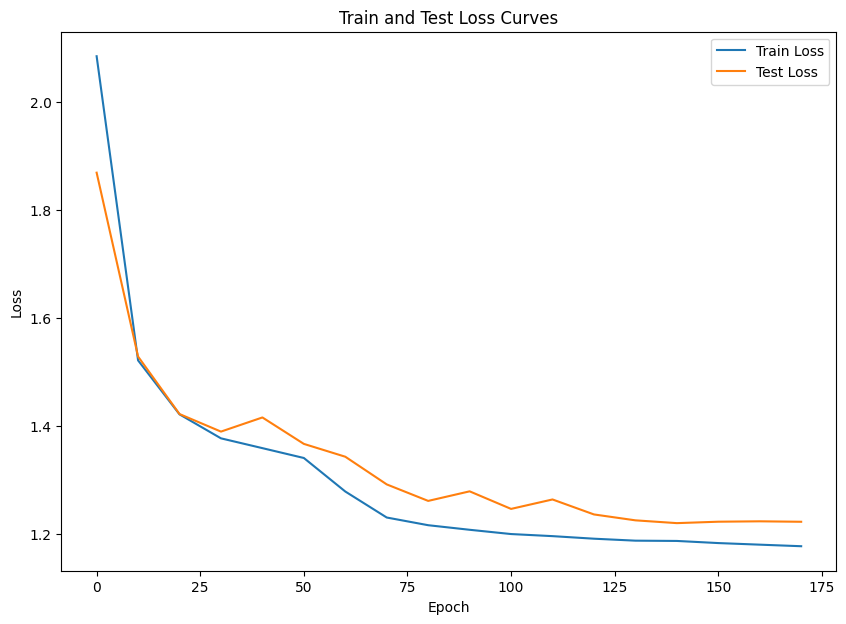

In [28]:
from deep_learning.plots import plot_loss_curve

plot_loss_curve(lst_epoch, lst_tr_loss, lst_te_loss)

In [29]:
from deep_learning.metrics import f1_score_fn
from deep_learning.inference import excu_inference

lst_te_y, lst_te_pred = excu_inference(
    early_stopper.get_best_model(), device, test_dataloader, f1_score_fn)


Test Dataset..:   0%|          | 0/157 [00:00<?, ?it/s]

f1_score_fn: 0.5557631656902011


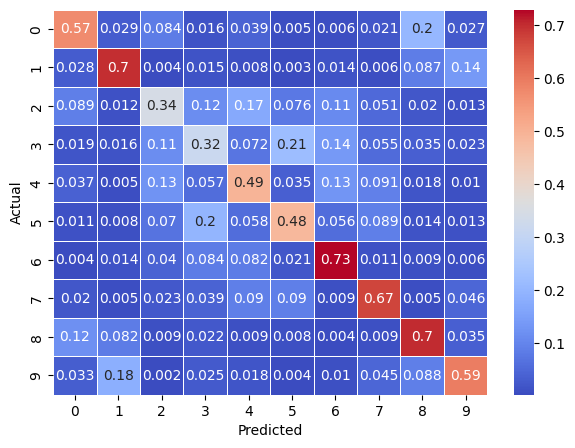

In [30]:
from deep_learning.plots import plot_heatmap

plot_heatmap(
    lst_te_y, lst_te_pred, train_dataset.classes)